# v2 · RSNA Pneumonia — классификатор ConvNeXt V2 Base

Классификатор рентгена грудной клетки на 3 класса: 0 — норма, 1 — изменения без пневмонии, 2 — пневмония.

**Отличия от v1:** ConvNeXt V2 Base вместо Tiny, аугментации включены, снимки 640×640, деление train / val = 80 / 20 (бывший test ушёл в обучение, итоговый тест — Kaggle).

**Итог на val:** лучший macro F1 **0.730** (эпоха 10), ROC-AUC ≈ 0.89. С аугментациями переобучение началось примерно с 10-й эпохи (в v1 — с 4-й), но качество осталось на уровне v1.

На выходе для ноутбука YOLO:
- `meta_classifier_ConvNeXt_V2_Base_with_aug.csv`, `boxes_640_classifier_ConvNeXt_V2_Base_with_aug.csv`
- `classifier_ConvNeXt_V2_Base_with_aug/classifier_best_for_f1_ConvNeXt_V2_Base_with_aug.pt`
- `classifier_ConvNeXt_V2_Base_with_aug/val_probs_ConvNeXt_V2_Base_with_aug.csv`

> Val здесь — другие 20% снимков, чем в v1, поэтому метрики на val с v1 напрямую не сравниваются. Сравнение версий — по Kaggle.

## 0. Установка и Google Drive

In [1]:
!pip install -q pydicom pylibjpeg pylibjpeg-libjpeg timm albumentations grad-cam

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Данные

Архив, таблица «снимок → класс» и таблица боксов.

In [3]:
import zipfile
from pathlib import Path

SEED = 42
drive_dir = Path("/content/drive/MyDrive/rsna_project_final")
drive_dir.mkdir(parents=True, exist_ok=True)

zip_path = Path("/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip")
extract_dir = Path("/content/extract_dir")
done_marker = extract_dir / ".done"

if done_marker.exists():
    print(f"Архив уже распакован в {extract_dir}")
else:
    print("Распаковываю архив...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    done_marker.touch()
    print("Архив успешно распакован!")

train_dir = extract_dir / "stage_2_train_images"
print("DICOM в train:", len(list(train_dir.glob("*.dcm"))))

Архив уже распакован в /content/extract_dir
DICOM в train: 26684


In [4]:
import pandas as pd
detector_info = pd.read_csv('/content/extract_dir/stage_2_train_labels.csv')
class_info = pd.read_csv('/content/extract_dir/stage_2_detailed_class_info.csv')

class_info.head()

,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


In [5]:
labels = class_info.drop_duplicates().reset_index(drop=True)

class_map = {
    "Normal": 0,
    "No Lung Opacity / Not Normal": 1,
    "Lung Opacity": 2,
}
labels["label"] = labels["class"].map(class_map)

assert len(labels) == labels.patientId.nunique() == 26684
assert labels["label"].isna().sum() == 0

labels["label"].value_counts().sort_index()

,count
label,
0,8851
1,11821
2,6012


In [6]:
boxes = detector_info[detector_info["Target"] == 1].drop(columns=["Target"]).reset_index(drop=True)

In [7]:
assert len(boxes) == 9555
assert boxes[["x", "y", "width", "height"]].notna().all().all()

pneumonia_ids = labels.loc[labels["label"] == 2, "patientId"]
assert boxes["patientId"].nunique() == len(pneumonia_ids)
assert boxes["patientId"].isin(pneumonia_ids).all()

Проекция AP/PA из заголовков DICOM — нужна для стратификации сплита.

In [8]:
import pydicom
from pathlib import Path

train_image_path = extract_dir / "stage_2_train_images"
metadata_list = []
target_tags = [
    "PatientID",
    "PhotometricInterpretation",
    "ViewPosition",
    "PatientSex",
    "PatientAge",
    "Rows",
    "Columns"
]

for file_path in train_image_path.glob("*.dcm"):
    try: # на случай ошибки dcmread
        ds = pydicom.dcmread(file_path, stop_before_pixels=True) # читаем только метаданные (без пикселей)
        file_data = {} # создаем словарь для текущего файла
        for tag in target_tags: # собираем нужные теги
            file_data[tag] = getattr(ds, tag, None) # getattr(ds, tag, None) вернет значение тега или None, если его нет
        metadata_list.append(file_data)

    except Exception as e:
        print(f"Ошибка при чтении файла {file_path.name}: {e}")

df = pd.DataFrame(metadata_list)
print(df.head(3))

                              PatientID PhotometricInterpretation  \
0  2458db44-f35a-4251-bebf-19514b25fd1c               MONOCHROME2   
1  6bc29d1f-fdf7-4c3a-ab66-c99f60d27bb8               MONOCHROME2   
2  ae7a7ed0-ea01-44de-9287-b2dec267bcfd               MONOCHROME2   

  ViewPosition PatientSex PatientAge  Rows  Columns  
0           PA          F         25  1024     1024  
1           AP          F         67  1024     1024  
2           AP          F         60  1024     1024  


In [9]:
df = df.rename(columns={'PatientID': 'patientId'}, inplace=False)
df.head()

,patientId,PhotometricInterpretation,ViewPosition,PatientSex,PatientAge,Rows,Columns
0,2458db44-f35a-4251-bebf-19514b25fd1c,MONOCHROME2,PA,F,25,1024,1024
1,6bc29d1f-fdf7-4c3a-ab66-c99f60d27bb8,MONOCHROME2,AP,F,67,1024,1024
2,ae7a7ed0-ea01-44de-9287-b2dec267bcfd,MONOCHROME2,AP,F,60,1024,1024
3,0a34d5d9-8c50-4b97-9c9c-e5d6ed862a3d,MONOCHROME2,AP,M,19,1024,1024
4,ef27c260-e68c-4da3-bb4b-bf2e11fc34b2,MONOCHROME2,PA,M,56,1024,1024


In [10]:
meta = pd.merge(labels, df, on="patientId", how="inner")
assert len(meta) == 26684

In [11]:
meta.drop(columns=["PhotometricInterpretation"], inplace=True)
meta.drop(columns=["Columns"], inplace=True)
meta.drop(columns=["Rows"], inplace=True)

## 2. Препроцессинг

`DICOM → перцентильный клип 0.5–99.5% → 0..255 uint8 → ресайз 640`. Все снимки складываются в массив в памяти (26 684 × 640 × 640 ≈ 10.9 ГБ).

In [12]:
import pydicom
import cv2
import numpy as np
import sys
def percentile_clip(data, lower_percentile=0.5, upper_percentile=99.5):
    # 1. Вычисляем значения порогов для заданных перцентилей
    low_val, high_val = np.percentile(data, [lower_percentile,upper_percentile])

    # 2. Обрезаем (клипаем) массив по этим значениям
    clipped_data = np.clip(data, low_val, high_val)

    return clipped_data
def read_dicom(dicom_path):
    dcm = pydicom.dcmread(dicom_path)

    img = dcm.pixel_array.astype('float32')  # Извлекаем матрицу пикселей
    if dcm.PhotometricInterpretation == "MONOCHROME1": #проверка на монохром, просто часть функции на будущее
        img = img.max() - img
    img = percentile_clip(img)
    img = (img - np.min(img)) / (np.max(img) - np.min(img) + sys.float_info.epsilon) # Нормализация в [0, 1] +защита от деления на ноль, в числителе все равно - будет просто черная картинка
    img = np.round(img * 255).astype(np.uint8) #растягиваем до 255 и потом uint8

    return img

def resize_img(img,size=512):
    resized_img = cv2.resize(img, (size,size), interpolation=cv2.INTER_AREA) #ресайз
    scale =  resized_img.shape[0]/img.shape[0]
    return resized_img, scale

def resize_boxes(df, scale):
    df1 = df.copy()
    cols = ['x', 'y', 'width', 'height']
    df1[cols] = df1[cols] * scale
    return df1

In [13]:
import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm
# Исходные данные
resize = 640
num_images = len(meta)
def process_single_patient(i, patient_id):

    image_after_read = read_dicom(train_image_path / (patient_id + ".dcm"))
    image_after_resize, scale_of_resize = resize_img(image_after_read, size=resize)

    return i, image_after_resize, scale_of_resize

images = np.zeros((num_images, resize, resize), dtype=np.uint8)

scales = [None] * num_images

with Parallel(n_jobs=-1, return_as="generator") as parallel:
    # Генератор задач для joblib
    tasks = (delayed(process_single_patient)(i, meta['patientId'][i]) for i in range(num_images))

    for i, img, scale in tqdm(parallel(tasks), total=num_images, desc="Processing DICOMs"):
        images[i] = img
        scales[i] = scale

last_scale = scales[-1]
resized_boxes = resize_boxes(boxes, scale=last_scale)


print(f"Размер массива в памяти: {images.nbytes / (1024**2):.2f} MB")

Processing DICOMs: 100%|██████████| 26684/26684 [03:15<00:00, 136.38it/s]

Размер массива в памяти: 10423.44 MB


## 3. Сплит train / val = 80 / 20

Стратификация по `класс + проекция`. Таблицы сохраняются для ноутбука YOLO.

In [14]:
from sklearn.model_selection import train_test_split
meta["strat_key"] = meta["label"].astype(str) + "_" + meta["ViewPosition"]
# отделяем test: 20% строк meta
train, val = train_test_split(meta, test_size=0.20, random_state=SEED,
                                   stratify=meta["strat_key"])

# одписываем строки meta
meta["split"] = "train"
meta.loc[val.index, "split"] = "val"

# проверка
print(meta["split"].value_counts())
print(pd.crosstab(meta["split"], meta["strat_key"], normalize="index").round(3))

# сохранить один раз для всех ноутбуков
meta.to_csv(drive_dir / "meta_classifier_ConvNeXt_V2_Base_with_aug.csv", index=False)
resized_boxes.to_csv(drive_dir / "boxes_640_classifier_ConvNeXt_V2_Base_with_aug.csv", index=False)

split
train    21347
val       5337
Name: count, dtype: int64
strat_key   0_AP  0_PA  1_AP   1_PA   2_AP   2_PA
split                                            
train      0.061  0.27  0.22  0.223  0.175  0.050
val        0.061  0.27  0.22  0.223  0.175  0.051


## 4. Dataset, аугментации, DataLoader

In [15]:
from torch.utils.data import Dataset, DataLoader
import torch

class CXRDataset(Dataset):
    def __init__(self, images, labels, indices, transform=None):
        self.images = images          # ссылка на весь массив (N, 512, 512), без копии
        self.labels = labels          # метки всех N строк, numpy-массив
        self.indices = indices        # номера строк этого датасета
        self.transform = transform

    def __len__(self):
        return len(self.indices)      # сколько снимков в ЭТОМ датасете

    def __getitem__(self, i):
        idx = self.indices[i]         # номер внутри датасета -> номер в общем массиве

        img = self.images[idx]        # только читаем, в общий массив не пишем
        label = self.labels[idx]

        if self.transform is not None:
            img = self.transform(image=img)["image"] # аугментация над локальной копией

        img = torch.from_numpy(img).float().div(255).unsqueeze(0)  # (1, 512, 512), 0..1
        label = torch.tensor(label, dtype=torch.long)
        return img, label

In [16]:
import albumentations as A

def get_transforms():
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05),
                 rotate=(-10, 10), p=0.7),
        A.Perspective(scale=(0.02, 0.05), p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),
        A.GaussNoise(std_range=(0.01, 0.04), p=0.2),
        A.CoarseDropout(num_holes_range=(1, 4),
                        hole_height_range=(0.04, 0.10),
                        hole_width_range=(0.04, 0.10),
                        fill=0, p=0.3),
    ])

In [17]:
import os
cores = os.cpu_count()

In [18]:
labels = meta["label"].values
train_indices = np.where(meta["split"] == "train")[0]
val_indices = np.where(meta["split"] == "val")[0]

train_ds = CXRDataset(images, labels, train_indices, transform = get_transforms())
val_ds = CXRDataset(images, labels, val_indices)

print(len(train_ds), len(val_ds))
x, y = val_ds[0]
print(x.shape, x.dtype, x.min().item(), x.max().item(), y)

21347 5337
torch.Size([1, 640, 640]) torch.float32 0.0 1.0 tensor(2)


In [19]:
train_loader = DataLoader(
    train_ds,
    batch_size=16,  # Base на 640: батч 64,32 не помещается в память
    shuffle=True,
    num_workers=cores,
    pin_memory=True,
    persistent_workers=True,
)
val_loader = DataLoader(
    val_ds,
    batch_size=16,
    shuffle=False,
    num_workers=cores,
    pin_memory=True,
    persistent_workers=True
)

## 5. Обучение

ConvNeXt V2 Base, `CrossEntropyLoss` с весами классов, AdamW + OneCycleLR, bf16, ограничение градиента. Сохраняются лучшая модель по macro F1 (+ вероятности на val) и лучшая по val loss; ранняя остановка по val loss.

In [20]:
class EarlyStopping:
    """Ранняя остановка обучения, если валидационный лосс не улучшается."""
    def __init__(self, patience=7, verbose=False, delta=0):
        """
        Args:
            patience (int): Сколько эпох ждать после последнего улучшения.
            verbose (bool): Если True, выводит сообщение о каждом улучшении.
            delta (float): Минимальное изменение, считающееся как улучшение.
            path (str): Путь для сохранения лучшей модели.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        """Сохраняет модель при уменьшении валидационного лосса."""
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...')
        torch.save(model.state_dict(), out_dir / "classifier_best_for_val_ConvNeXt_V2_Base_with_aug.pt")
        self.val_loss_min = val_loss

In [21]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from pathlib import Path
from sklearn.metrics import roc_auc_score, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

# настройки
MODEL_NAME = "convnextv2_base.fcmae_ft_in22k_in1k_384"
EPOCHS = 20
LR = 1e-4
WEIGHT_DECAY = 0.05
MEAN, STD = 0.449, 0.226 # нормализация ImageNet для одного канала
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
out_dir = Path("/content/drive/MyDrive/rsna_project_final/classifier_ConvNeXt_V2_Base_with_aug")
out_dir.mkdir(parents=True, exist_ok=True)

# модель, ошибка, оптимизатор
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=3, in_chans=1,
                          drop_rate=0.2, drop_path_rate=0.1).to(DEVICE)

train_labels = labels[train_indices]
weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_labels)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR( # dynamic lr
    optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)

use_amp = DEVICE == "cuda"   # bf16 на GPU, обычный fp32 на CPU

# обучение
best_f1, history = -1.0, []

early_stopping = EarlyStopping(patience=8, verbose=True)

for epoch in range(EPOCHS):
    start = time.time()

    # --- эпоха обучения ---
    model.train()
    train_loss, n = 0.0, 0
    for x, y in tqdm(train_loader, leave=False, desc=f"train {epoch}"):
        x = ((x - MEAN) / STD).to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
            logits = model(x)
        loss = criterion(logits.float(), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        train_loss += loss.item() * len(x)
        n += len(x)
    train_loss /= n

    # --- валидация ---
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in tqdm(val_loader, leave=False, desc=f"val {epoch}"):
            x = ((x - MEAN) / STD).to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
                logits = model(x)
            probs.append(torch.softmax(logits.float(), dim=1).cpu())
            ys.append(y)
    probs = torch.cat(probs).numpy()           # (N_val, 3)
    ys = torch.cat(ys).numpy()                 # (N_val,)
    preds = probs.argmax(1)

    val_loss = nn.functional.nll_loss(torch.log(torch.tensor(probs).clamp_min(1e-8)),
                                      torch.tensor(ys)).item()
    auc = roc_auc_score(ys, probs, multi_class="ovr")
    f1 = f1_score(ys, preds, average="macro")
    rec2 = recall_score(ys, preds, labels=[2], average="macro")
    # --- запись в историю ---
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        auc=auc, f1=f1, rec2=rec2))
    print(f"ep {epoch} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | auc {auc:.4f} | "
          f"f1 {f1:.4f} | rec2 {rec2:.4f} | {time.time() - start:.0f}s")

    # --- лучшая эпоха: веса и вероятности на val ---
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), out_dir / "classifier_best_for_f1_ConvNeXt_V2_Base_with_aug.pt")
        val_df = meta.iloc[val_indices][["patientId", "label", "ViewPosition"]].copy()
        val_df[["prob0", "prob1", "prob2"]] = probs
        val_df.to_csv(out_dir / "val_probs_ConvNeXt_V2_Base_with_aug.csv", index=False)

    # --- проверка Early Stopping ---
    early_stopping(val_loss, model)

    if early_stopping.early_stop:
        print("Ранняя остановка сработала. Обучение прекращено.")
        break

pd.DataFrame(history).to_csv(out_dir / "history_ConvNeXt_V2_Base_with_aug.csv", index=False)
print(f"лучший macro F1: {best_f1:.4f}")

train 0:   0%|          | 0/1335 [00:01<?, ?it/s]

val 0:   0%|          | 0/334 [00:02<?, ?it/s]

ep 0 | train_loss 0.7441 | val_loss 0.6201 | auc 0.8798 | f1 0.7083 | rec2 0.5428 | 729s
Validation loss decreased (inf --> 0.620058). Saving model ...


train 1:   0%|          | 0/1335 [00:00<?, ?it/s]

val 1:   0%|          | 0/334 [00:00<?, ?it/s]

...

val 13:   0%|          | 0/334 [00:00<?, ?it/s]

ep 13 | train_loss 0.2399 | val_loss 0.9614 | auc 0.8782 | f1 0.7125 | rec2 0.6401 | 721s
EarlyStopping counter: 7 out of 8


train 14:   0%|          | 0/1335 [00:00<?, ?it/s]

val 14:   0%|          | 0/334 [00:00<?, ?it/s]

ep 14 | train_loss 0.1990 | val_loss 1.1376 | auc 0.8785 | f1 0.7120 | rec2 0.6467 | 721s
EarlyStopping counter: 8 out of 8
Ранняя остановка сработала. Обучение прекращено.
лучший macro F1: 0.7300


## 6. Grad-CAM

Куда смотрит модель. Код из [jacobgil/pytorch-grad-cam](https://github.com/jacobgil/pytorch-grad-cam).

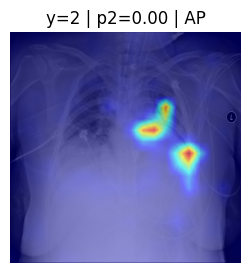

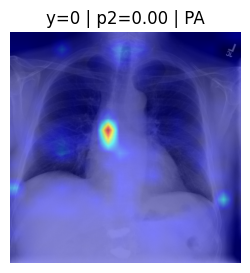

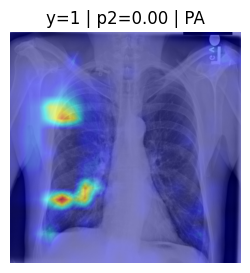

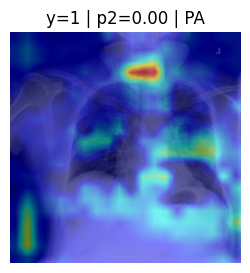

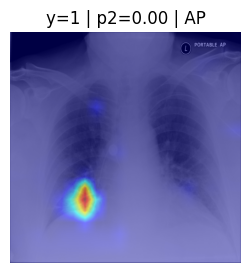

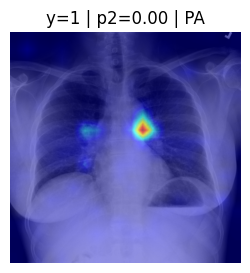

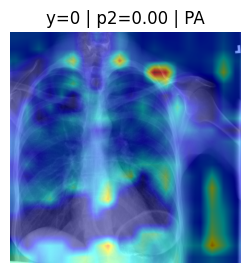

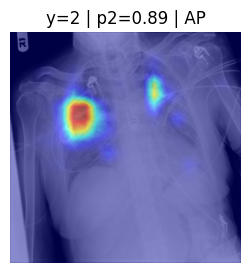

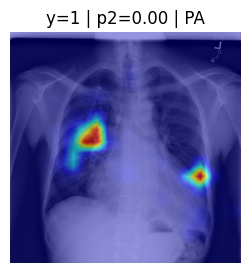

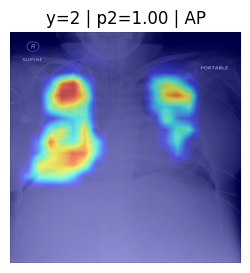

In [22]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np
import torch

target_layers = [model.stages[-1]]
for y in range(10):
    i = val_indices[y] # номер снимка в images
    img = images[i] # (512, 512) uint8
    input_tensor = ((torch.from_numpy(img).float().div(255)[None, None] - MEAN) / STD).to(DEVICE)
    rgb_img = np.repeat(img[..., None], 3, axis=2).astype(np.float32) / 255   # серый -> (H, W, 3), 0..1

    # We have to specify the target we want to generate the CAM for.
    targets = [ClassifierOutputTarget(2)]
    # Construct the CAM object once, and then re-use it on many images.
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
        # In this example grayscale_cam has only one image in the batch:
        grayscale_cam = grayscale_cam[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        # You can also get the model outputs without having to redo inference
        model_outputs = cam.outputs

    p2 = torch.softmax(model_outputs, dim=1)[0, 2].item()
    plt.figure(figsize=(3, 3))
    plt.imshow(visualization)
    plt.title(f"y={meta.iloc[i].label} | p2={p2:.2f} | {meta.iloc[i].ViewPosition}")
    plt.axis("off")
    plt.show()

## 7. Порог по коэффициенту Жаккара на val

лучший порог prob2: 0.38 | Жаккар на val: 0.4716


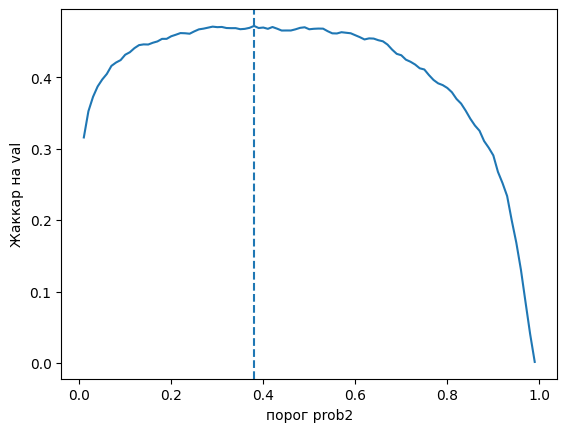

In [23]:
from sklearn.metrics import jaccard_score

def best_jaccard_threshold(y_true, p, thresholds=np.linspace(0.01, 0.99, 99)):
    """Порог по вероятности, при котором Жаккар максимален. Все пороги считаются разом."""
    y = np.asarray(y_true, dtype=bool)
    pred = np.asarray(p)[None, :] >= thresholds[:, None]      # (число порогов, число снимков)
    tp = (pred & y).sum(1)
    fp = (pred & ~y).sum(1)
    fn = (~pred & y).sum(1)
    jac = tp / np.maximum(tp + fp + fn, 1)
    i = jac.argmax()
    return thresholds[i], jac[i], thresholds, jac


# подбор на val
val = pd.read_csv(out_dir / "val_probs_ConvNeXt_V2_Base_with_aug.csv")
thr, j_val, ts, js = best_jaccard_threshold(val["label"] == 2, val["prob2"])
print(f"лучший порог prob2: {thr:.2f} | Жаккар на val: {j_val:.4f}")

plt.plot(ts, js)
plt.axvline(thr, ls="--")
plt.xlabel("порог prob2"); plt.ylabel("Жаккар на val")
plt.show()